# Coastal, ocean and climate meshes with `pyramids-mesh`

Ocean circulation, storm-surge and global-climate models each store their unstructured grid in
their **own file format**. `pyramids-mesh` ships one *driver* per format whose only job is to
parse the file and hand back a `pyramids.netcdf.ugrid` object — a `UgridDataset` (a 2D surface
mesh) or a `Network1d` (a 1D channel network). No GIS, no interpolation: just the reader.

This tutorial reads one real committed sample of each of nine formats, inspects the topology it
produced, and draws it. The formats fall into three families:

- **Coastal / storm-surge triangulations** — SCHISM, FVCOM, ADCIRC (lon/lat, finite-element).
- **Global climate grids** — MPAS, ICON, SCRIP, ESMF, GEOS (whole-sphere, often in *radians*).
- **1D hydraulic networks** — Deltares D-Flow FM (a channel graph, not a surface mesh).

Every sample under `examples/data/<fmt>/` carries a `SOURCE.txt` naming its provenance and licence.

## Set up the plotting backend

We render through `matplotlib` (via `cleopatra`). So the notebook runs identically in CI and
interactively, we pin the non-interactive **`Agg`** backend *before* importing `pyplot` — this
writes figures into the notebook instead of opening a GUI window. The `from pyramids...` import
also satisfies the package's import-order contract (importing pyramids is what puts the vendored
GDAL/OGR bindings on the path). `DATA` points two levels up, at the repo-root `examples/data/`.

In [1]:
import os; os.environ["MPLBACKEND"] = "Agg"
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from pyramids.netcdf.ugrid import UgridDataset
DATA = Path("../../examples/data")

### Two small helpers

Under the `Agg` backend figures must be rendered to PNG explicitly, so `show()` embeds the
current figure into the notebook. `mesh_info()` collapses the four facts we care about — node
count, face count, CRS and data-variable names — into a one-row table. Per-variable statistics
come from the dataset's own `summary()` method.

In [2]:
import pandas as pd
from io import BytesIO
from IPython.display import Image, display

def show(dpi=110):
    buf = BytesIO()
    plt.gcf().savefig(buf, format="png", dpi=dpi, bbox_inches="tight")
    plt.close("all"); display(Image(data=buf.getvalue()))

def mesh_info(ds):
    return pd.DataFrame({"n_node": [ds.n_node], "n_face": [ds.n_face],
        "crs": [str(ds.crs)],
        "data_vars": [", ".join(ds.data_variable_names) or "(none)"]})

## 1. SCHISM — `hgrid.gr3`

**SCHISM** (Semi-implicit Cross-scale Hydroscience Integrated System Model) is a finite-element
coastal-ocean model. Its horizontal grid lives in an ASCII `hgrid.gr3` file: a node list with a
depth per node, then a triangle/quad connectivity table, then open- and land-boundary sections.
The driver returns those as a `UgridDataset` whose node depth is exposed as `node_z`.

In [3]:
schism = UgridDataset.read_file(str(DATA / "schism" / "hgrid.gr3"), driver="schism")
schism

C:\python-environments\pixi\envs\pyramids-mesh-4081970794675243037\envs\dev\Lib\site-packages\pyramids\netcdf\ugrid\_drivers.py:538: RuntimeWarning: Mesh driver 'dfsu' (pyramids_mesh.drivers.dhi:DfsuDriver) could not be loaded and was skipped: ModuleNotFoundError("No module named 'mikeio'")
  driver = _instantiate(entry_point)


UgridDataset(mesh='mesh2d', n_node=2639, n_face=4636, n_edge=0, variables=['node_z'])

In [4]:
display(mesh_info(schism))
display(schism.summary())

,n_node,n_face,crs,data_vars
0,2639,4636,None,node_z


,count,min,max,mean,std
variable,,,,,
node_z,2639,0.5,10.0,4.41068,2.799775


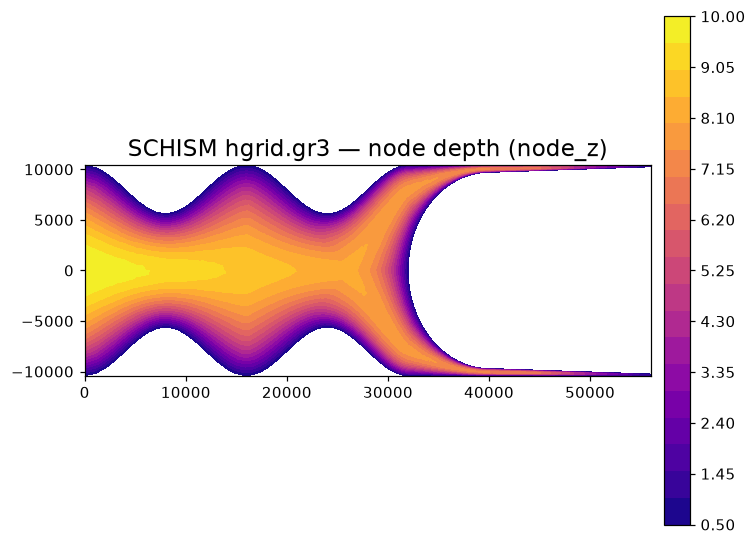

In [5]:
schism.plot("node_z", cmap="plasma", colorbar=True,
            title="SCHISM hgrid.gr3 — node depth (node_z)")
show()

The mesh has **2,639 nodes / 4,636 triangles**. `crs` is `None`: the `.gr3` format carries no
CRS, so the driver preserves the node coordinates verbatim in the file's native units (here a
local teaching-domain planform). The colour map is the per-node bathymetry — the depth that
drives the hydrodynamics — painted across the triangulation, so the mesh refinement near the
channel is visible as the denser-coloured band.

## 2. FVCOM — `chn_grd.dat`

**FVCOM** (Finite-Volume Community Ocean Model) uses an unstructured triangular grid defined by a
trio of ASCII files. The driver reads the grid file `*_grd.dat` (node coordinates + triangle
connectivity); the companion `chn_dep.dat` supplies per-node bathymetry, surfaced again as
`node_z`. FVCOM's finite-volume scheme makes it a workhorse for estuaries and tidal channels.

In [6]:
fvcom = UgridDataset.read_file(str(DATA / "fvcom" / "chn_grd.dat"), driver="fvcom")
fvcom

UgridDataset(mesh='mesh2d', n_node=871, n_face=1620, n_edge=0, variables=['node_z'])

In [7]:
display(mesh_info(fvcom))
display(fvcom.summary())

,n_node,n_face,crs,data_vars
0,871,1620,None,node_z


,count,min,max,mean,std
variable,,,,,
node_z,871,10.0,100.0,86.526924,26.648772


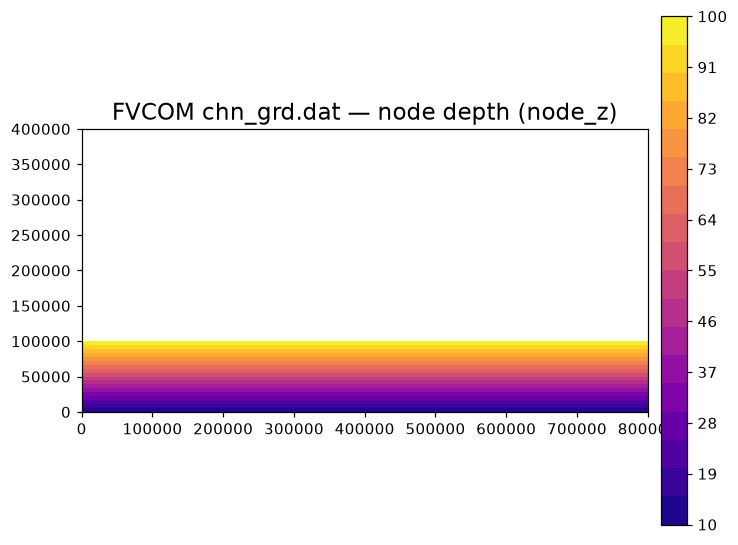

In [8]:
fvcom.plot("node_z", cmap="plasma", colorbar=True,
           title="FVCOM chn_grd.dat — node depth (node_z)")
show()

**871 nodes / 1,620 triangles** — a small idealised channel. As with SCHISM the format is
CRS-free (`crs = None`), so coordinates stay in the file's native units. The depth field shades
from the shallow banks to the deeper thalweg, and the triangle density tracks where the modeller
wanted resolution.

## 3. ADCIRC — `fort.14`

**ADCIRC** is the storm-surge and tidal model of record for the US coast. Its mesh file
`fort.14` shares the same ASCII layout as SCHISM's `.gr3`. This is the classic **Shinnecock
Inlet** example (Long Island, NY), so its coordinates are genuine **lon/lat degrees**. The file
also carries a result field, `zeta` (sea-surface elevation), alongside the node depth.

In [9]:
adcirc = UgridDataset.read_file(str(DATA / "adcirc" / "fort.14"), driver="adcirc")
adcirc

UgridDataset(mesh='mesh2d', n_node=3070, n_face=5780, n_edge=0, variables=['zeta', 'node_z'])

In [10]:
display(mesh_info(adcirc))
display(adcirc.summary())

,n_node,n_face,crs,data_vars
0,3070,5780,None,"zeta, node_z"


,count,min,max,mean,std
variable,,,,,
zeta,173936,-0.587433,0.627106,0.014328,0.338818
node_z,3070,-2.342191,57.560005,27.422450,16.496160


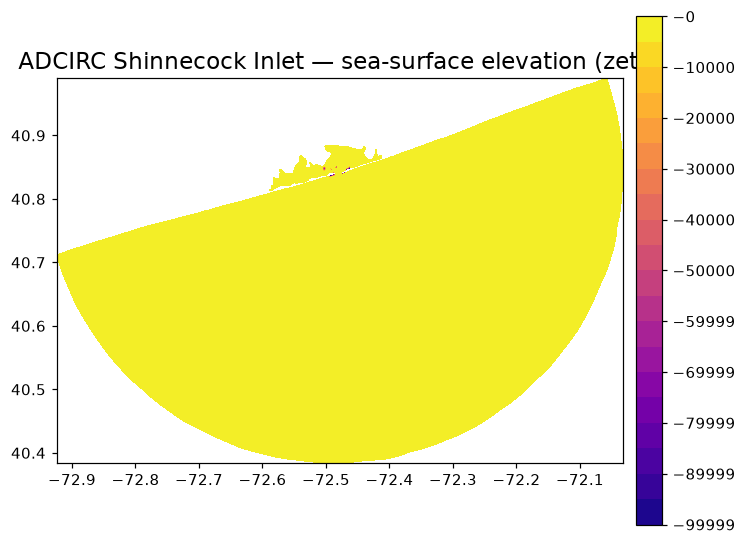

In [11]:
adcirc.plot("zeta", cmap="plasma", colorbar=True,
            title="ADCIRC Shinnecock Inlet — sea-surface elevation (zeta)")
show()

**3,070 nodes / 5,780 triangles** over the Shinnecock Inlet. The x/y axes are longitude and
latitude in degrees (`crs` is still reported as `None` because the ASCII header states no EPSG
code, but the summary's coordinate ranges are clearly geographic). The first data variable is
`zeta`, the modelled sea-surface elevation; `plot` renders its first time slice over the mesh,
revealing the set-up of water through the narrow inlet.

## 4. MPAS — `mesh.QU.1920km.151026.nc`

**MPAS** (Model for Prediction Across Scales) tiles the sphere with a mostly-hexagonal
(Voronoi) mesh — the dynamical core behind several climate and weather models. This quasi-uniform
1920 km mesh is deliberately coarse (162 cells, with 12 pentagons among the hexagons). The driver
reads the `verticesOnCell` connectivity and builds polygonal faces. **Coordinates are in radians.**

In [12]:
mpas = UgridDataset.read_file(str(DATA / "mpas" / "mesh.QU.1920km.151026.nc"), driver="mpas")
mpas

C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 13 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)


UgridDataset(mesh='mesh2d', n_node=320, n_face=162, n_edge=0, variables=[])

In [13]:
display(mesh_info(mpas))  # data_vars is empty: this file is pure topology

,n_node,n_face,crs,data_vars
0,320,162,None,(none)


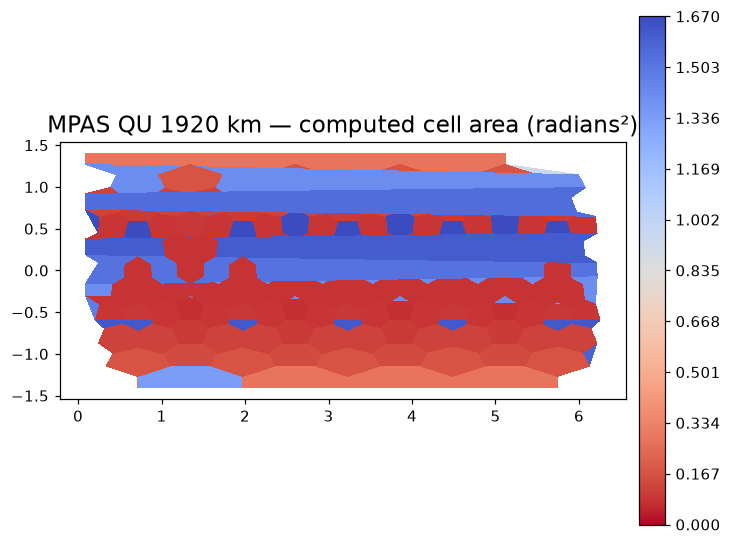

In [14]:
mpas_a = mpas.with_variable("cell_area", np.asarray(mpas.mesh.face_areas), location="face")
mpas_a.plot("cell_area", cmap="viridis", colorbar=True,
            title="MPAS QU 1920 km — computed cell area (radians²)")
show()

**320 vertices / 162 faces.** This file is *pure geometry* — `data_variable_names` is empty — so
to get a colour map we compute each face's area from the mesh itself (`mesh.face_areas`) and
attach it with `with_variable(..., location="face")`. The x-axis runs 0–2π because MPAS stores
longitude/latitude in **radians**, not degrees. The hexagons are near-uniform in size; the 12
pentagons (needed to close a sphere with hexagons) show up as the slightly smaller cells.

## 5. ICON — `icon_grid_R02B04_subset.nc`

**ICON** (ICOsahedral Nonhydrostatic) is the DWD/MPI global model, built on a triangular grid
derived from a refined icosahedron. This is a 320-cell subset of the R02B04 grid. The file ships
its own `cell_area` variable, so no computation is needed. Like MPAS, **coordinates are in
radians** (`clon`/`clat`, `vlon`/`vlat`).

In [15]:
icon = UgridDataset.read_file(str(DATA / "icon" / "icon_grid_R02B04_subset.nc"), driver="icon")
icon

UgridDataset(mesh='mesh2d', n_node=197, n_face=320, n_edge=0, variables=['cell_area'])

In [16]:
display(mesh_info(icon))
display(icon.summary())

,n_node,n_face,crs,data_vars
0,197,320,None,cell_area


,count,min,max,mean,std
variable,,,,,
cell_area,320,1.877728e+10,2.568455e+10,2.477042e+10,1.004190e+09


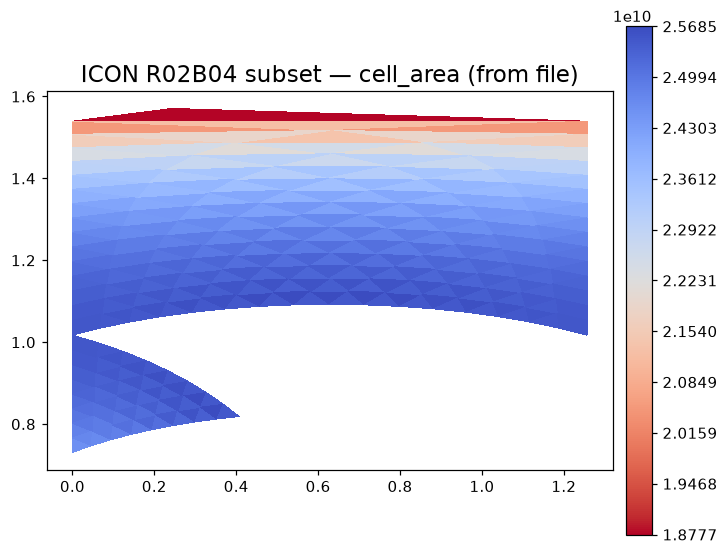

In [17]:
icon.plot("cell_area", cmap="viridis", colorbar=True,
          title="ICON R02B04 subset — cell_area (from file)")
show()

**197 vertices / 320 triangular cells.** Unlike MPAS this grid carries a genuine `cell_area`
field in the file, which the summary table quantifies and the plot paints across the triangles.
The coordinate axes are again in radians. ICON's triangles are the duals of MPAS's hexagons —
two different tessellations of the same icosahedral refinement strategy.

## 6. SCRIP — `outCSne8.nc`

**SCRIP** (Spherical Coordinate Remapping and Interpolation Package) is not a model grid but a
*grid-description* convention used to define source/target grids for conservative remapping
between climate components. A SCRIP file lists each cell by its corner lon/lat
(`grid_corner_lat`/`grid_corner_lon`). This sample is a cubed-sphere **ne8** grid.

In [18]:
scrip = UgridDataset.read_file(str(DATA / "scrip" / "outCSne8.nc"), driver="scrip")
scrip

UgridDataset(mesh='mesh2d', n_node=407, n_face=384, n_edge=0, variables=[])

In [19]:
display(mesh_info(scrip))  # a remapping grid description: geometry only

,n_node,n_face,crs,data_vars
0,407,384,None,(none)


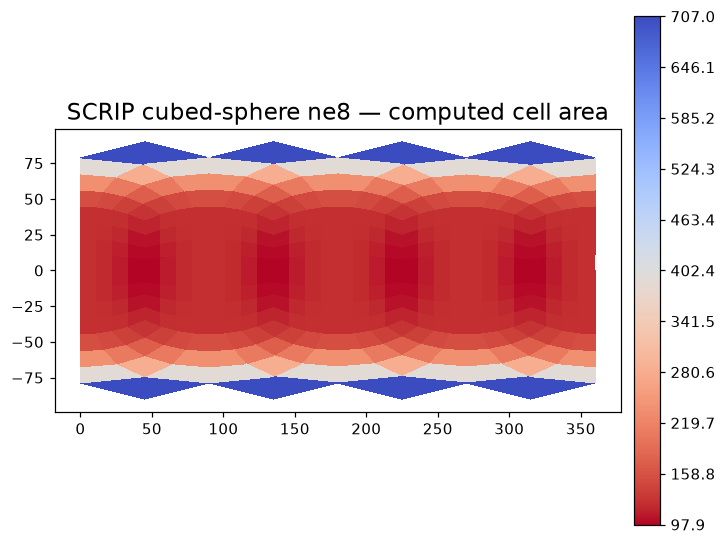

In [20]:
scrip_a = scrip.with_variable("cell_area", np.asarray(scrip.mesh.face_areas), location="face")
scrip_a.plot("cell_area", cmap="viridis", colorbar=True,
             title="SCRIP cubed-sphere ne8 — computed cell area")
show()

**407 nodes / 384 faces** — the six faces of a cubed sphere, each diced into an 8×8 block
(6×8×8 = 384). SCRIP files hold only geometry, so again we attach a computed `cell_area`. The
colour map makes the cubed-sphere distortion visible: cells near the cube-face corners are
smaller than those at the face centres, which is exactly the area variation a conservative
remapper must account for.

## 7. ESMF — `ne4np4-esmf.nc`

**ESMF** (Earth System Modeling Framework) defines its own unstructured-mesh NetCDF convention
(`nodeCoords`, `elementConn`, `numElementConn`) used to couple Earth-system model components.
This is the canonical `ne4np4` example mesh. Only the classic CDF-1 variant is readable by the
vendored GDAL; this sample is that variant.

In [21]:
esmf = UgridDataset.read_file(str(DATA / "esmf" / "ne4np4-esmf.nc"), driver="esmf")
esmf

C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 24 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)


UgridDataset(mesh='mesh2d', n_node=866, n_face=936, n_edge=0, variables=[])

In [22]:
display(mesh_info(esmf))  # ESMF mesh description: geometry only

,n_node,n_face,crs,data_vars
0,866,936,None,(none)


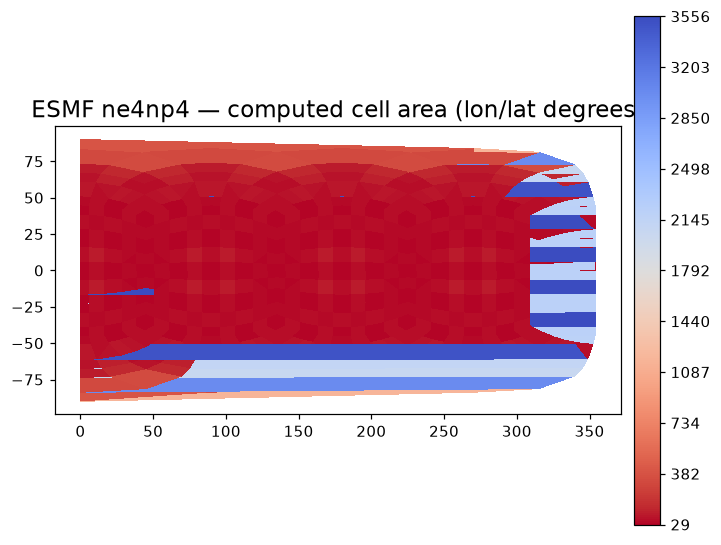

In [23]:
esmf_a = esmf.with_variable("cell_area", np.asarray(esmf.mesh.face_areas), location="face")
esmf_a.plot("cell_area", cmap="viridis", colorbar=True,
            title="ESMF ne4np4 — computed cell area (lon/lat degrees)")
show()

**866 nodes / 936 elements.** The ESMF mesh is a geometry-only description, so we colour it by
computed `cell_area`. These coordinates are **lon/lat in degrees** (x spans 0–360), so the whole
globe is laid out flat. The gentle area gradient across each cube face is the same cubed-sphere
signature seen in the SCRIP grid.

## 8. GEOS — `test-c12.native.nc4`

**GEOS** (the NASA GMAO Earth-system model) stores its native cubed-sphere grid as corner
longitude/latitude arrays shaped `(6, N+1, N+1)` — six cube faces, each an N×N block of cells.
The driver reconstructs the cell connectivity by index arithmetic. This is the coarse **C12**
resolution.

In [24]:
geos = UgridDataset.read_file(str(DATA / "geos" / "test-c12.native.nc4"), driver="geos")
geos

C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 26 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)


UgridDataset(mesh='mesh2d', n_node=1014, n_face=864, n_edge=0, variables=[])

In [25]:
display(mesh_info(geos))  # native cubed-sphere corners: geometry only

,n_node,n_face,crs,data_vars
0,1014,864,None,(none)


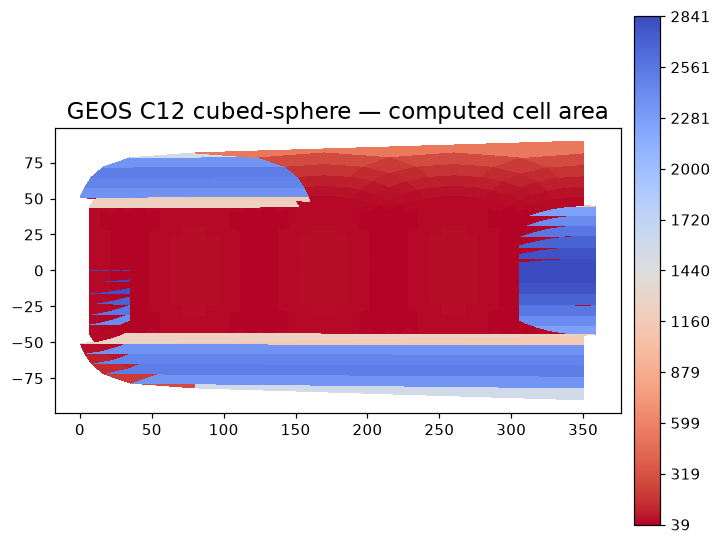

In [26]:
geos_a = geos.with_variable("cell_area", np.asarray(geos.mesh.face_areas), location="face")
geos_a.plot("cell_area", cmap="viridis", colorbar=True,
            title="GEOS C12 cubed-sphere — computed cell area")
show()

**1,014 nodes / 864 faces** (6×12×12 = 864 cells). Reconstructed from corner arrays and coloured
by computed area, the plot shows the six cube faces unrolled in lon/lat. GEOS, SCRIP and ESMF are
three different file encodings of essentially the same cubed-sphere idea — a good illustration of
why a format layer like `pyramids-mesh` is useful: one `UgridDataset` API, many on-disk dialects.

## 9. Deltares 1D network — `korte-woerden-1d_FlowFM_net.nc`

Everything above is a 2D *surface* mesh. A **Deltares D-Flow FM** `*_net.nc` file can instead
describe a **1D channel network**: nodes joined by edges (branches), with no faces at all. Because
its topology dimension is 1, `UgridDataset.read_file` would refuse it — we read it with
**`Network1d.read_file`**, which returns a `Network1d` (nodes + edges + a CRS), not a `Mesh2d`.
So we explore it as a *graph*, never calling face-based methods on it.

In [27]:
from pyramids.netcdf.ugrid import Network1d
net = Network1d.read_file(str(DATA / "deltares1d" / "korte-woerden-1d_FlowFM_net.nc"),
                          driver="deltares1d")
net

C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:624: UserWarning: Network1d carries a topology and a CRS only, so mesh1d_node_branch, mesh1d_node_offset, global_attributes could not be attached to this 1D mesh and are not in the result
  self._warn_network_drops(parsed)


In [28]:
edge_len = np.asarray(net.edge_lengths)
pd.DataFrame({"n_node": [net.n_node], "n_edge": [net.n_edge], "crs": [str(net.crs)],
              "directed": [net.directed],
              "edge_len_min_m": [round(float(edge_len.min()), 2)],
              "edge_len_max_m": [round(float(edge_len.max()), 2)]})

,n_node,n_edge,crs,directed,edge_len_min_m,edge_len_max_m
0,86,91,28992,False,0.1,217.99


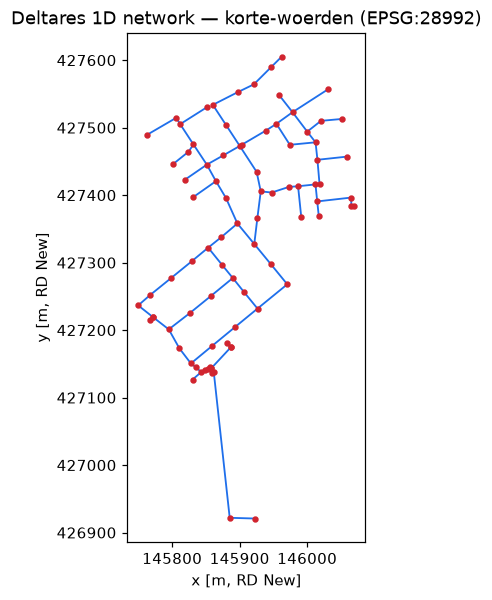

In [29]:
nx, ny = np.asarray(net.node_x), np.asarray(net.node_y)
enc = np.asarray(net.edge_node_connectivity.data)
fig, ax = plt.subplots(figsize=(7, 6))
for a, b in enc:
    ax.plot([nx[a], nx[b]], [ny[a], ny[b]], color="#1f6feb", lw=1.2)
ax.scatter(nx, ny, s=10, color="#d1242f", zorder=3)
ax.set_aspect("equal"); ax.set_title("Deltares 1D network — korte-woerden (EPSG:28992)")
ax.set_xlabel("x [m, RD New]"); ax.set_ylabel("y [m, RD New]")
show()

**86 nodes / 91 edges**, and crucially **no faces** — asking this object for `n_face` raises,
because a 1D network has none. Unlike the ocean/climate grids above, this one *does* carry a CRS:
`EPSG:28992` (Amersfoort / RD New), so its coordinates are **projected metres** over the
Netherlands, not lon/lat. We draw it by hand from `node_x`/`node_y` and the
`edge_node_connectivity` edge list — a branching channel graph (`directed = False`) with branch
lengths from 0.1 m up to ~218 m. This is the shape of a drainage or canal network, the 1D
counterpart to the 2D surface meshes.

---

### Recap

Nine formats, one API. Coastal triangulations (SCHISM, FVCOM, ADCIRC), global climate grids
(MPAS, ICON, SCRIP, ESMF, GEOS) and a 1D hydraulic network (Deltares) all parsed into
`pyramids.netcdf.ugrid` objects — `UgridDataset` for surfaces, `Network1d` for graphs. Watch the
coordinate convention: most ocean/climate grids are CRS-free lon/lat, MPAS and ICON are in
radians, and the Deltares network is projected metres (EPSG:28992).